<a href="https://colab.research.google.com/github/bandapraneeth/Quantum-Hackathon/blob/main/question_62.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
from sklearn.datasets import load_diabetes, make_friedman1

# Dataset 1: Diabetes Regression D07
diabetes = load_diabetes(as_frame=True)
df_diabetes = diabetes.frame
df_diabetes.to_csv("diabetes_D07.csv", index=False)

# Dataset 2: Friedman-1 Regression D08
X_friedman, y_friedman = make_friedman1(
    n_samples=500,
    n_features=10,
    noise=1.0,
    random_state=42
)

df_friedman = pd.DataFrame(
    X_friedman,
    columns=[f"feature_{i+1}" for i in range(10)]
)

df_friedman["target"] = y_friedman
df_friedman.to_csv("friedman1_D08.csv", index=False)

print("Both datasets created successfully")
print("Diabetes:", df_diabetes.shape)
print("Friedman:", df_friedman.shape)


Both datasets created successfully
Diabetes: (442, 11)
Friedman: (500, 11)


In [ ]:

from google.colab import files

files.download("diabetes_D07.csv")
files.download("friedman1_D08.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install -q qiskit qiskit-aer scipy scikit-learn pandas matplotlib


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_diabetes, make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from scipy.optimize import minimize

np.random.seed(42)

simulator = AerSimulator()
SHOTS = 256

print("Libraries initialized")


Libraries initialized


In [ ]:

diabetes = load_diabetes()

X_diabetes = diabetes.data
y_diabetes = diabetes.target

print("X shape:", X_diabetes.shape)
print("Y shape:", y_diabetes.shape)


X shape: (442, 10)
Y shape: (442,)


In [ ]:

X_friedman, y_friedman = make_friedman1(
    n_samples=500,
    n_features=10,
    noise=1.0,
    random_state=42
)

print("X shape:", X_friedman.shape)
print("Y shape:", y_friedman.shape)


X shape: (500, 10)
Y shape: (500,)


In [ ]:

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_diabetes, y_diabetes,
    test_size=0.2,
    random_state=42
)

# Fit scaling only on training partition
x_scaler_d = StandardScaler()
X_train_d = x_scaler_d.fit_transform(X_train_d)
X_test_d = x_scaler_d.transform(X_test_d)

y_scaler_d = StandardScaler()
y_train_d = y_scaler_d.fit_transform(
    y_train_d.reshape(-1, 1)
).ravel()

y_test_d_scaled = y_scaler_d.transform(
    y_test_d.reshape(-1, 1)
).ravel()

# Reduce 10 features to 4 quantum input features
pca_d = PCA(n_components=4)
X_train_d = pca_d.fit_transform(X_train_d)
X_test_d = pca_d.transform(X_test_d)

# Map features to rotation angles
angle_scaler_d = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_d = angle_scaler_d.fit_transform(X_train_d)
X_test_d = angle_scaler_d.transform(X_test_d)

print("Diabetes preprocessing completed")


Diabetes preprocessing completed


In [ ]:

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_friedman, y_friedman,
    test_size=0.2,
    random_state=42
)

x_scaler_f = StandardScaler()
X_train_f = x_scaler_f.fit_transform(X_train_f)
X_test_f = x_scaler_f.transform(X_test_f)

y_scaler_f = StandardScaler()
y_train_f = y_scaler_f.fit_transform(
    y_train_f.reshape(-1, 1)
).ravel()

y_test_f_scaled = y_scaler_f.transform(
    y_test_f.reshape(-1, 1)
).ravel()

pca_f = PCA(n_components=4)
X_train_f = pca_f.fit_transform(X_train_f)
X_test_f = pca_f.transform(X_test_f)

angle_scaler_f = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_f = angle_scaler_f.fit_transform(X_train_f)
X_test_f = angle_scaler_f.transform(X_test_f)

print("Friedman preprocessing completed")


Friedman preprocessing completed


In [ ]:

N_QUBITS = 4
N_PARAMS = 8

def create_qcl_circuit(x, params):

    qc = QuantumCircuit(N_QUBITS, N_QUBITS)

    # Data encoding
    for i in range(N_QUBITS):
        qc.rx(x[i], i)

    # Trainable layer
    for i in range(N_QUBITS):
        qc.ry(params[i], i)

    # Entanglement
    for i in range(N_QUBITS - 1):
        qc.cx(i, i + 1)

    # Second trainable layer
    for i in range(N_QUBITS):
        qc.ry(params[i + N_QUBITS], i)

    # Measure all qubits
    qc.measure(range(N_QUBITS), range(N_QUBITS))

    return qc

print("Quantum circuit function created")


Quantum circuit function created


In [ ]:

def quantum_predict_one(x, params, shots=SHOTS):

    qc = create_qcl_circuit(x, params)

    compiled = transpile(qc, simulator)

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    # Expectation value of Z on qubit 0
    total = sum(counts.values())
    expectation = 0

    for bitstring, count in counts.items():
        bit = int(bitstring[-1])
        z_value = 1 if bit == 0 else -1
        expectation += z_value * count

    expectation /= total

    return expectation, qc


In [ ]:

params = np.random.uniform(-np.pi, np.pi, N_PARAMS)

prediction, circuit = quantum_predict_one(
    X_train_d[0],
    params
)

print("Quantum prediction:", prediction)
print("Qubits:", circuit.num_qubits)
print("Circuit depth:", circuit.depth())

print(circuit.draw(output="text"))


Quantum prediction: -0.171875
Qubits: 4
Circuit depth: 7
      ┌────────────┐┌──────────────┐     ┌─────────────┐               ┌─┐»
q_0: ─┤ Rx(1.0166) ├┤ Ry(-0.78829) ├──■──┤ Ry(-2.1613) ├───────────────┤M├»
     ┌┴────────────┤└┬────────────┬┘┌─┴─┐└─────────────┘┌─────────────┐└╥┘»
q_1: ┤ Rx(-0.2522) ├─┤ Ry(2.8319) ├─┤ X ├───────■───────┤ Ry(-2.1615) ├─╫─»
     ├─────────────┤ ├────────────┤ └───┘     ┌─┴─┐     └─────────────┘ ║ »
q_2: ┤ Rx(0.23315) ├─┤ Ry(1.4577) ├───────────┤ X ├────────────■────────╫─»
     └┬────────────┤┌┴────────────┤           └───┘          ┌─┴─┐      ║ »
q_3: ─┤ Rx(2.0289) ├┤ Ry(0.61989) ├──────────────────────────┤ X ├──────╫─»
      └────────────┘└─────────────┘                          └───┘      ║ »
c: 4/═══════════════════════════════════════════════════════════════════╩═»
                                                                        0 »
«                             
«q_0: ────────────────────────
«                    ┌─┐      
«q_1: ────────

In [ ]:

def objective(params, X, y, shots=SHOTS):

    predictions = []

    for x in X:
        pred, _ = quantum_predict_one(x, params, shots)
        predictions.append(pred)

    predictions = np.array(predictions)

    mse = np.mean((predictions - y) ** 2)

    return mse


In [ ]:

X_qtrain_d = X_train_d[:60]
y_qtrain_d = y_train_d[:60]

initial_params = np.random.uniform(
    -np.pi, np.pi, N_PARAMS
)

start_time = time.time()

training_result_d = minimize(
    objective,
    initial_params,
    args=(X_qtrain_d, y_qtrain_d, 64),
    method="COBYLA",
    options={"maxiter": 20}
)

training_time_d = time.time() - start_time

trained_params_d = training_result_d.x

print("Training completed")
print("Final objective:", training_result_d.fun)
print("Optimizer iterations:", training_result_d.nfev)
print("Training time:", training_time_d)


Training completed
Final objective: 0.8374724612871378
Optimizer iterations: 20
Training time: 208.03629446029663


In [ ]:

X_qtrain_f = X_train_f[:60]
y_qtrain_f = y_train_f[:60]

initial_params_f = np.random.uniform(
    -np.pi, np.pi, N_PARAMS
)

start_time = time.time()

training_result_f = minimize(
    objective,
    initial_params_f,
    args=(X_qtrain_f, y_qtrain_f, 64),
    method="COBYLA",
    options={"maxiter": 20}
)

training_time_f = time.time() - start_time

trained_params_f = training_result_f.x

print("Friedman training completed")
print("Final objective:", training_result_f.fun)
print("Optimizer iterations:", training_result_f.nfev)
print("Training time:", training_time_f)


Friedman training completed
Final objective: 0.8311486812378156
Optimizer iterations: 20
Training time: 221.89823651313782


In [ ]:

def quantum_predict(X, params, shots=SHOTS):

    predictions = []

    for x in X:
        pred, _ = quantum_predict_one(x, params, shots)
        predictions.append(pred)

    return np.array(predictions)


In [ ]:

start = time.time()

pred_d_scaled = quantum_predict(
    X_test_d[:30],
    trained_params_d,
    shots=64
)

inference_time_d = time.time() - start

pred_d = y_scaler_d.inverse_transform(
    pred_d_scaled.reshape(-1, 1)
).ravel()

actual_d = y_scaler_d.inverse_transform(
    y_test_d_scaled[:30].reshape(-1, 1)
).ravel()

print("Diabetes predictions completed")
print("Inference time:", inference_time_d)


Diabetes predictions completed
Inference time: 9.940754890441895


In [ ]:

start = time.time()

pred_f_scaled = quantum_predict(
    X_test_f[:30],
    trained_params_f,
    shots=64
)

inference_time_f = time.time() - start

pred_f = y_scaler_f.inverse_transform(
    pred_f_scaled.reshape(-1, 1)
).ravel()

actual_f = y_scaler_f.inverse_transform(
    y_test_f_scaled[:30].reshape(-1, 1)
).ravel()

print("Friedman predictions completed")
print("Inference time:", inference_time_f)


Friedman predictions completed
Inference time: 17.591410160064697


In [ ]:

def regression_metrics(actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    residuals = actual - predicted
    residual_bias = np.mean(residuals)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Residual Bias": residual_bias
    }

metrics_d = regression_metrics(actual_d, pred_d)
metrics_f = regression_metrics(actual_f, pred_f)

print("Diabetes metrics:", metrics_d)
print("Friedman metrics:", metrics_f)


Diabetes metrics: {'MAE': 85.71758803475804, 'RMSE': np.float64(96.85576813371446), 'R2': -0.3237126571118656, 'Residual Bias': np.float64(-11.992958051753213)}
Friedman metrics: {'MAE': 4.540164744927319, 'RMSE': np.float64(5.4139407151661185), 'R2': -0.17950159071016558, 'Residual Bias': np.float64(-0.8965209157899381)}


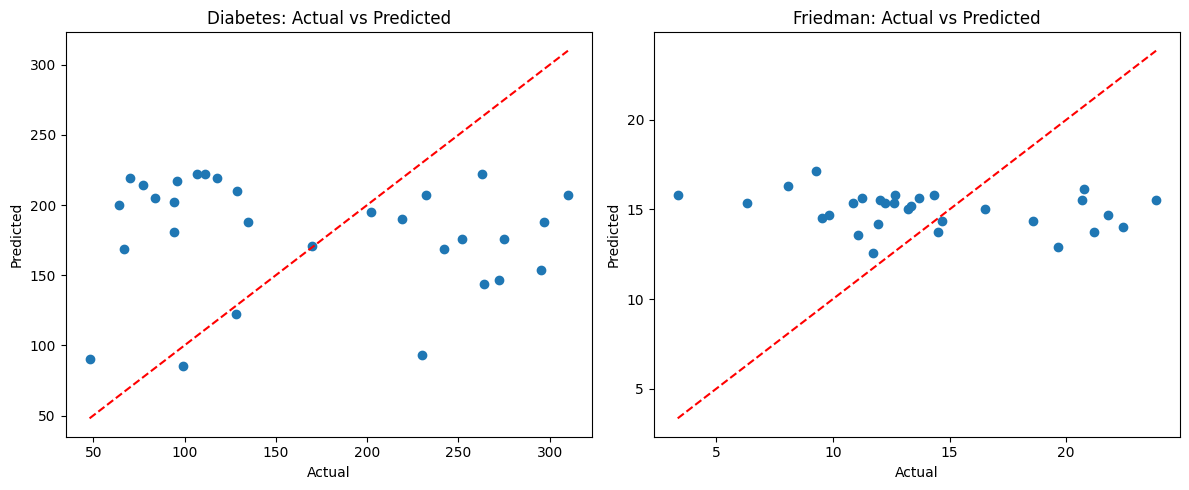

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(actual_d, pred_d)
axes[0].plot(
    [actual_d.min(), actual_d.max()],
    [actual_d.min(), actual_d.max()],
    "r--"
)
axes[0].set_title("Diabetes: Actual vs Predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

axes[1].scatter(actual_f, pred_f)
axes[1].plot(
    [actual_f.min(), actual_f.max()],
    [actual_f.min(), actual_f.max()],
    "r--"
)
axes[1].set_title("Friedman: Actual vs Predicted")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")

plt.tight_layout()
plt.show()


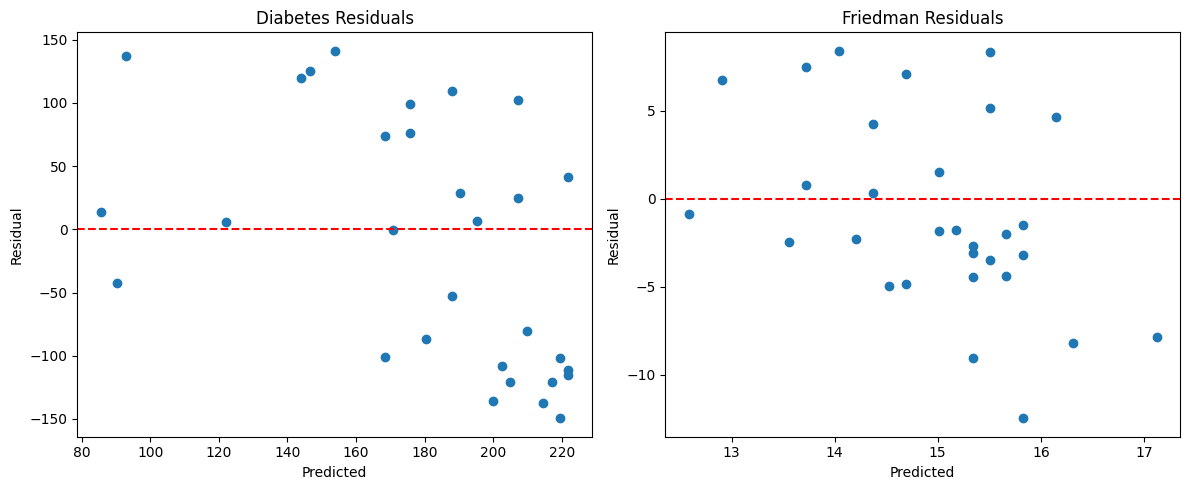

In [ ]:

residuals_d = actual_d - pred_d
residuals_f = actual_f - pred_f

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(pred_d, residuals_d)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Diabetes Residuals")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Residual")

axes[1].scatter(pred_f, residuals_f)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Friedman Residuals")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()


In [ ]:

metrics_table = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "Residual Bias"],
    "Diabetes": [
        metrics_d["MAE"],
        metrics_d["RMSE"],
        metrics_d["R2"],
        metrics_d["Residual Bias"]
    ],
    "Friedman": [
        metrics_f["MAE"],
        metrics_f["RMSE"],
        metrics_f["R2"],
        metrics_f["Residual Bias"]
    ]
})

display(metrics_table.round(4))


,Metric,Diabetes,Friedman
0,MAE,85.7176,4.5402
1,RMSE,96.8558,5.4139
2,R2,-0.3237,-0.1795
3,Residual Bias,-11.9930,-0.8965


In [ ]:

_, sample_circuit = quantum_predict_one(
    X_train_d[0],
    trained_params_d,
    shots=64
)

quantum_cost = pd.DataFrame({
    "Parameter": [
        "Qubits",
        "Modes/Register states",
        "Circuit depth",
        "Shots",
        "Circuit evaluations",
        "Optimizer iterations",
        "Training time (s)",
        "Inference time (s)"
    ],

    "Diabetes": [
        N_QUBITS,
        2,
        sample_circuit.depth(),
        64,
        training_result_d.nfev * len(X_qtrain_d),
        training_result_d.nfev,
        training_time_d,
        inference_time_d
    ],

    "Friedman": [
        N_QUBITS,
        2,
        sample_circuit.depth(),
        64,
        training_result_f.nfev * len(X_qtrain_f),
        training_result_f.nfev,
        training_time_f,
        inference_time_f
    ]
})

display(quantum_cost.round(3))


,Parameter,Diabetes,Friedman
0,Qubits,4.000,4.000
1,Modes/Register states,2.000,2.000
2,Circuit depth,7.000,7.000
3,Shots,64.000,64.000
4,Circuit evaluations,1200.000,1200.000
5,Optimizer iterations,20.000,20.000
6,Training time (s),208.036,221.898
7,Inference time (s),9.941,17.591


In [ ]:

_, sample_circuit = quantum_predict_one(
    X_train_d[0],
    trained_params_d,
    shots=64
)

quantum_cost = pd.DataFrame({
    "Parameter": [
        "Qubits",
        "Modes/Register states",
        "Circuit depth",
        "Shots",
        "Circuit evaluations",
        "Optimizer iterations",
        "Training time (s)",
        "Inference time (s)"
    ],

    "Diabetes": [
        N_QUBITS,
        2,
        sample_circuit.depth(),
        64,
        training_result_d.nfev * len(X_qtrain_d),
        training_result_d.nfev,
        training_time_d,
        inference_time_d
    ],

    "Friedman": [
        N_QUBITS,
        2,
        sample_circuit.depth(),
        64,
        training_result_f.nfev * len(X_qtrain_f),
        training_result_f.nfev,
        training_time_f,
        inference_time_f
    ]
})

display(quantum_cost.round(3))


,Parameter,Diabetes,Friedman
0,Qubits,4.000,4.000
1,Modes/Register states,2.000,2.000
2,Circuit depth,7.000,7.000
3,Shots,64.000,64.000
4,Circuit evaluations,1200.000,1200.000
5,Optimizer iterations,20.000,20.000
6,Training time (s),208.036,221.898
7,Inference time (s),9.941,17.591


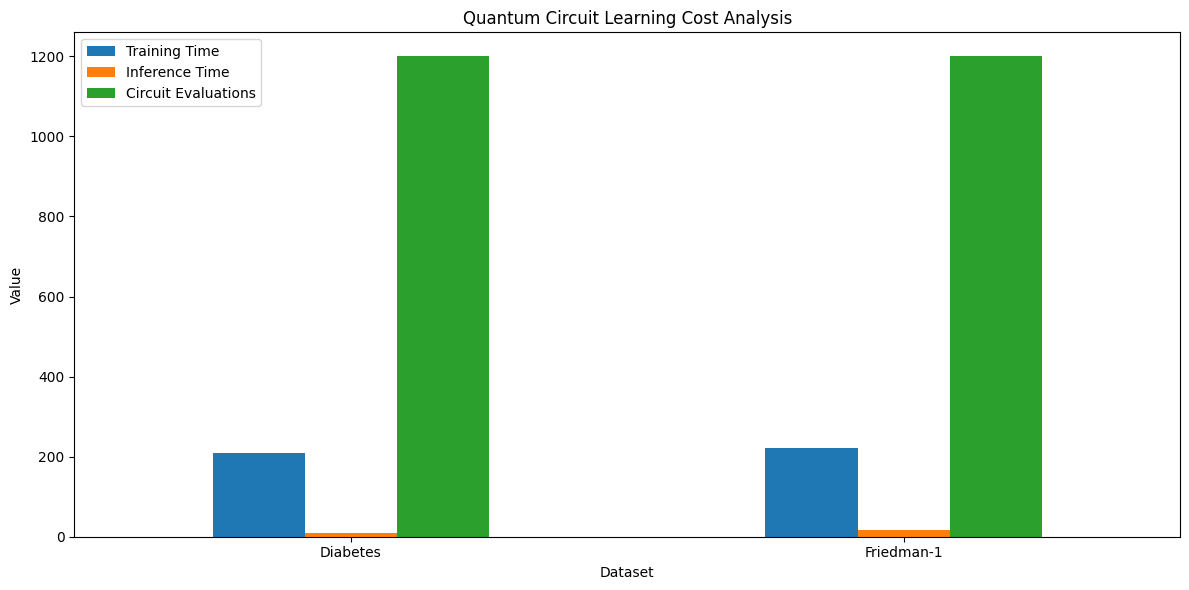

In [ ]:

cost_plot = pd.DataFrame({
    "Dataset": ["Diabetes", "Friedman-1"],
    "Training Time": [training_time_d, training_time_f],
    "Inference Time": [inference_time_d, inference_time_f],
    "Circuit Evaluations": [
        training_result_d.nfev * len(X_qtrain_d),
        training_result_f.nfev * len(X_qtrain_f)
    ]
})

cost_plot.set_index("Dataset").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Quantum Circuit Learning Cost Analysis")
plt.ylabel("Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

metrics_table.to_csv(
    "QCL_regression_metrics.csv",
    index=False
)

quantum_cost.to_csv(
    "QCL_quantum_cost.csv",
    index=False
)

print("Results saved successfully")


Results saved successfully


In [ ]:

from google.colab import files

files.download("QCL_regression_metrics.csv")
files.download("QCL_quantum_cost.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>